# Lab 5: Motor parameter identification

I ran the experiment on both wheels of robot: wheel 3 (big wheel, port M3, encoder E3) and wheel 4 (small wheel, port M4, encoder E4). The robot was on a stand, so the wheels spun freely. For every PWM level from -100 % to +100 % in 5 % steps, the program in `motor_identification.qrs` applied the step, logged time and encoder angle for 2 s, and wrote the battery voltage into the file header. The raw files are in `motor_data/`.

Model from the lecture, for a voltage step $U$ from rest:

$$\theta(t) = \omega_{ss}\left(t - T_m + T_m e^{-t/T_m}\right), \qquad \omega_{ss} = \frac{U}{k_e}, \qquad U = \frac{PWM}{100}\,U_{battery}$$

In [1]:
import os, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.integrate import odeint

In [2]:
DATA = "motor_data"
if not os.path.isdir(DATA):  # in Colab: upload the zip with the robot files
    from google.colab import files
    zipfile.ZipFile(list(files.upload())[0]).extractall(DATA)


def read_run(wheel, pwm):
    path = f"{DATA}/wheel_{wheel}_v_{pwm}.txt"
    with open(path) as f:
        battery = float(f.readlines()[2].split(":")[1])  # 3rd line: "# battery_voltage: ..."
    t_ms, deg = np.loadtxt(path, comments="#", unpack=True)
    return t_ms / 1000, np.radians(deg), battery          # SI: s, rad, V

Saving motor_data_A17_0vbe16yx.zip to motor_data_A17_0vbe16yx.zip


## 1. Fitting $\theta(t)$

Each run is fitted with `curve_fit`. Time is not shifted, because t = 0 in the files is the moment the power was applied. As a starting guess for $\omega_{ss}$ I use the average speed of the run (last angle / last time), since with `p0=[8, 0.1]` from the example the fit for wheel 4 at 100 % gave a wrong result.

In [3]:
def theta_model(t, w_ss, T_m):
    return w_ss * (t - T_m + T_m * np.exp(-t / T_m))


levels = list(range(-100, 0, 5)) + list(range(5, 105, 5))  # 0 % is not tested
rows = []
for w in (3, 4):
    for p in levels:
        t, theta, battery = read_run(w, p)
        (w_ss, T_m), _ = curve_fit(theta_model, t, theta, p0=[theta[-1] / t[-1], 0.2])
        rows.append(dict(wheel=w, PWM=p, U=p / 100 * battery, w_ss=w_ss, T_m=T_m))
res = pd.DataFrame(rows)

## 2. $T_m$ [s] and $\omega_{ss}$ [rad/s] for every PWM level

In [4]:
res.pivot(index="PWM", columns="wheel", values=["w_ss", "T_m"]).round(3)

w_ss            T_m       
wheel       3       4      3      4
PWM                                
-100  -14.658 -13.945  0.052  0.042
-95   -14.285 -13.454  0.078  0.055
-90   -13.619 -12.627  0.107  0.079
-85   -13.001 -11.881  0.138  0.104
-80   -12.634 -11.525  0.138  0.114
-75   -12.324 -11.084  0.158  0.120
-70   -11.582 -10.328  0.182  0.126
-65   -10.879  -9.587  0.240  0.151
-60   -10.658  -9.280  0.253  0.170
-55   -10.094  -8.819  0.255  0.174
-50    -9.824  -8.594  0.297  0.186
-45    -9.464  -8.227  0.305  0.192
-40    -8.989  -7.767  0.306  0.189
-35    -8.639  -7.371  0.348  0.243
-30    -7.453  -6.287  0.367  0.250
-25    -6.584  -5.721  0.130  0.253
-20    -5.908  -4.930  0.392  0.262
-15    -5.193  -3.769  0.459  0.233
-10    -3.830  -3.528  0.428  0.399
-5     -1.279  -1.247  0.385  0.181
 5      1.107   1.803  0.420  0.343
 10     4.327   3.803  0.690  0.372
 15     5.475   4.819  0.592  0.312
 20     6.135   5.656  0.411  0.318
 25     7.050   6.313  0.431  0.290
 30     7.395   6.982  0.163  0.279
 35     8.752   8.028  0.334  0.233
 40     9.171   8.448  0.300  0.222
 45     9.643   8.868  0.301  0.208
 50    10.002   9.297  0.286  0.212
 55    10.301   9.645  0.263  0.201
 60    10.814  10.221  0.232  0.176
 65    11.123  10.428  0.237  0.161
 70    11.860  11.317  0.186  0.140
 75    12.554  12.120  0.169  0.127
 80    12.997  12.586  0.157  0.111
 85    13.253  13.001  0.129  0.095
 90    13.879  13.881  0.097  0.093
 95    14.568  14.826  0.064  0.065
 100   14.994  15.408  0.064  0.044

## 3. $\omega_{ss}$ vs $U$: $k_e$ and the dead zone

$k_e$ is 1 / slope of a straight line through $\omega_{ss}(U)$. Both wheels already turn at ±5 %, so the dead zone is smaller than one PWM step. I estimate its edges by extending the line through the 5 % and 10 % points down to $\omega = 0$.

wheel 3: k_e = 0.669 V*s/rad, T_m = 0.25 s, dead zone -0.28 to +0.37 V
wheel 4: k_e = 0.712 V*s/rad, T_m = 0.18 s, dead zone -0.26 to +0.06 V


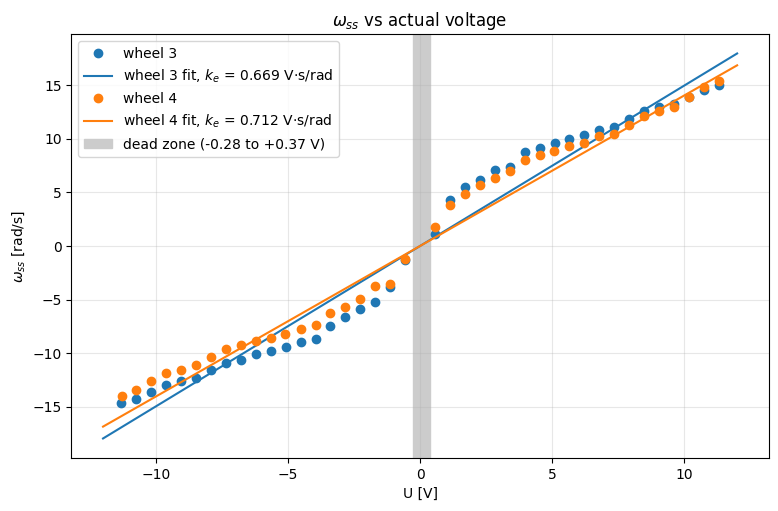

In [5]:
ke, Tm, dz = {}, {}, []
U_line = np.array([-12, 12])
plt.figure(figsize=(9, 5.5))
for w in (3, 4):
    r = res[res.wheel == w].set_index("PWM")
    ke[w] = 1 / np.polyfit(r.U, r.w_ss, 1)[0]  # slope of w_ss(U) is 1/k_e
    Tm[w] = r.T_m.median()
    for s in (-1, 1):  # reverse, forward
        (U1, w1), (U2, w2) = r.loc[[5 * s, 10 * s], ["U", "w_ss"]].values
        dz.append(U1 - w1 * (U2 - U1) / (w2 - w1))  # line through both points, where w = 0
    print(f"wheel {w}: k_e = {ke[w]:.3f} V*s/rad, T_m = {Tm[w]:.2f} s, "
          f"dead zone {dz[-2]:+.2f} to {dz[-1]:+.2f} V")
    dots, = plt.plot(r.U, r.w_ss, "o", label=f"wheel {w}")
    plt.plot(U_line, U_line / ke[w], color=dots.get_color(), label=f"wheel {w} fit, $k_e$ = {ke[w]:.3f} V·s/rad")

plt.axvspan(min(dz), max(dz), color="0.8", label=f"dead zone ({min(dz):+.2f} to {max(dz):+.2f} V)")
plt.gca().set(xlabel="U [V]", ylabel=r"$\omega_{ss}$ [rad/s]", title=r"$\omega_{ss}$ vs actual voltage")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 4. Simulation vs measurement

The identified motor for wheel 3 ($k_e$ and median $T_m$ from above) simulated with `odeint` for the 50 % step, next to the measurement.

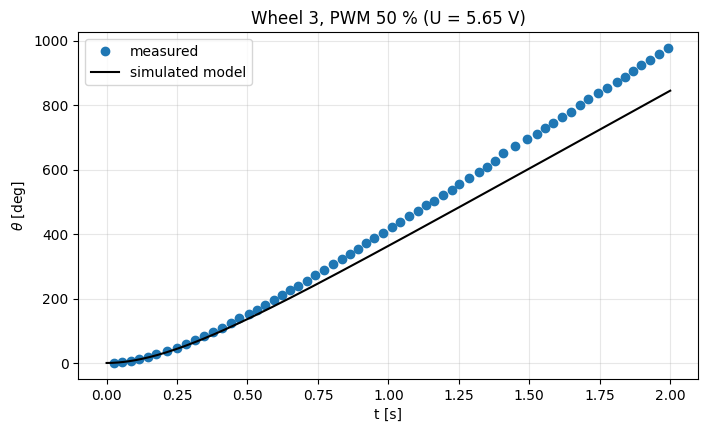

In [6]:
def motor(state, t, U, T_m, k_e):
    omega, theta = state
    return [(U / k_e - omega) / T_m, omega]  # T_m*dw/dt + w = U/k_e,  dtheta/dt = w


t, theta, battery = read_run(3, 50)
U = 0.5 * battery
t_sim = np.linspace(0, 2, 200)
sim = odeint(motor, [0, 0], t_sim, args=(U, Tm[3], ke[3]))

plt.figure(figsize=(8, 4.5))
plt.plot(t, np.degrees(theta), "o", label="measured")
plt.plot(t_sim, np.degrees(sim[:, 1]), "k", label="simulated model")
plt.gca().set(xlabel="t [s]", ylabel=r"$\theta$ [deg]", title=f"Wheel 3, PWM 50 % (U = {U:.2f} V)")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## Discussion

**Where the linear model fails.** The points in the $\omega_{ss}$ vs $U$ plot do not lie on a straight line: at +10 % the line predicts 1.7 rad/s but wheel 3 actually spins at 4.3 rad/s, and at +100 % it predicts 17 rad/s instead of 15. $T_m$ is not constant either: it is 0.2 to 0.7 s at low PWM and only about 0.05 s at ±100 %. The dead zone is small, since both wheels already turn at ±5 %.

**How much the wheels differ.** At the same PWM wheel 3 spins faster (10.0 vs 9.3 rad/s at +50 %, $k_e$ = 0.669 vs 0.712) and reacts more slowly ($T_m$ 0.25 vs 0.18 s), which makes sense because it is the bigger wheel with more inertia.

